## BRCA Feature Engineering

Exploring biologically valid features that may provide more info or non-linear relationships for BRCA1 variant classification

goal is to create and validate interpretable features; understand its distribution and relationship with existing features; identify redundany or unnecessary derived features and decide on potential features to be included in processed dataset 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

df = pd.read_csv("../data/raw/dataset.csv")
df.shape, df.columns

((1600, 24),
 Index(['variation_id', 'gene_symbol', 'protein_change', 'protein_position',
        'ref_aa', 'alt_aa', 'clinical_significance', 'domain', 'plddt',
        'is_stop_gained', 'is_frameshift', 'is_splice_region', 'label',
        'pos_norm', 'distance_to_domain', 'plddt_at_pos', 'plddt_window11',
        'hydro_delta', 'charge_delta', 'volume_delta', 'domain_BRCT1',
        'domain_BRCT2', 'domain_OTHER', 'domain_RING'],
       dtype='str'))

In [3]:
df.head()

,variation_id,gene_symbol,protein_change,protein_position,ref_aa,alt_aa,clinical_significance,domain,plddt,is_stop_gained,is_frameshift,is_splice_region,label,pos_norm,distance_to_domain,plddt_at_pos,plddt_window11,hydro_delta,charge_delta,volume_delta,domain_BRCT1,domain_BRCT2,domain_OTHER,domain_RING
0,100000,BRCA1,p.C176G,176,C,G,Benign,OTHER,61.795453,0,0,0,0,0.094471,67,52.778104,57.752886,2.9,0,48.4,False,False,True,False
1,100001,BRCA1,p.F773W,773,F,W,Benign,OTHER,50.859371,0,0,0,0,0.414922,664,59.417299,49.856908,3.7,0,37.9,False,False,True,False
2,100002,BRCA1,p.R1244W,1244,R,W,Benign,OTHER,54.256865,0,0,0,0,0.667740,402,46.864676,51.135601,3.6,1,54.4,False,False,True,False
3,100003,BRCA1,p.L36C,36,L,C,Pathogenic,RING,87.909717,0,0,0,1,0.019324,0,89.439383,83.145249,1.3,0,58.2,False,False,False,True
4,100004,BRCA1,p.I1205V,1205,I,V,Likely benign,OTHER,63.506025,0,0,0,0,0.646806,441,63.869783,56.117647,0.3,0,26.7,False,False,True,False


Existing important features -

#### Positional features
- `protein_position`
- `pos_norm`
- `distance_to_domain`
- `domain`

#### Structural features
- `plddt`
- `plddt_at_pos`
- `plddt_window11`

#### Amino-acid substitution features
- `ref_aa`
- `alt_aa`
- `hydro_delta`
- `charge_delta`
- `volume_delta`

#### Variant consequence flags
- `is_stop_gained`
- `is_frameshift`
- `is_splice_region`


### Derived features exploration

In [4]:
# plddt_delta = plddt_at_po - plddt_wondow11
df["plddt_delta"] = (df["plddt_at_pos"] - df["plddt_window11"])
df[["protein_position","plddt_at_pos","plddt_window11", "plddt_delta"]].head(10)

,protein_position,plddt_at_pos,plddt_window11,plddt_delta
0,176,52.778104,57.752886,-4.974782
1,773,59.417299,49.856908,9.560391
2,1244,46.864676,51.135601,-4.270925
3,36,89.439383,83.145249,6.294134
4,1205,63.869783,56.117647,7.752136
5,332,43.476604,45.877090,-2.400485
6,1653,90.494384,91.529545,-1.035160
7,1033,55.980145,55.209197,0.770949
8,1630,58.053104,58.717517,-0.664412
9,381,49.492464,44.857150,4.635313


In [8]:
# Assuming that plddt_window11 is the avg of 10 neighboring residues + the residue itself
df["plddt_neighbor_mean_est"] = ((df["plddt_window11"] * 11) - df["plddt_at_pos"]) / 10

df[["protein_position","plddt_at_pos","plddt_window11","plddt_neighbor_mean_est"]].head(10)

,protein_position,plddt_at_pos,plddt_window11,plddt_neighbor_mean_est
0,176,52.778104,57.752886,58.250364
1,773,59.417299,49.856908,48.900869
2,1244,46.864676,51.135601,51.562693
3,36,89.439383,83.145249,82.515836
4,1205,63.869783,56.117647,55.342433
5,332,43.476604,45.877090,46.117138
6,1653,90.494384,91.529545,91.633061
7,1033,55.980145,55.209197,55.132102
8,1630,58.053104,58.717517,58.783958
9,381,49.492464,44.857150,44.393619


In [10]:
# plddt score ranges from 0 to 100:
df[(df["plddt_neighbor_mean_est"] < 0) |(df["plddt_neighbor_mean_est"] > 100)][["protein_position","plddt_at_pos","plddt_window11","plddt_neighbor_mean_est"]]

,protein_position,plddt_at_pos,plddt_window11,plddt_neighbor_mean_est


In [9]:
df["plddt_neighbor_mean_est"].describe().round(2)

count    1600.00
mean       57.51
std        13.57
min        39.87
25%        47.53
50%        54.61
75%        59.90
max        93.75
Name: plddt_neighbor_mean_est, dtype: float64

In [ ]:
df["plddt_neighbor_delta"] = (df["plddt_at_pos"] -df["plddt_neighbor_mean_est"])
df["plddt_neighbor_delta"].describe().round(2)

count    1600.00
mean        0.14
std         6.35
min       -24.95
25%        -4.19
50%         0.20
75%         4.18
max        19.36
Name: plddt_neighbor_delta, dtype: float64

positive value - current residue has higher confidence than neighboring residues

negative value - current residue has lower confidence than neighboring residues

near zero - current residue is similar to its surrounding structural context

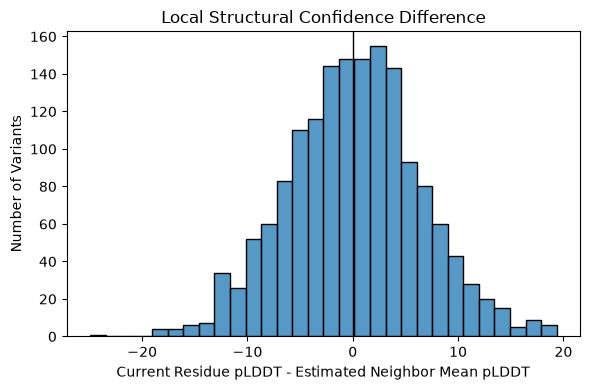

In [13]:
plt.figure(figsize=(6, 4))
sns.histplot(data=df,x="plddt_neighbor_delta",bins=30)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Current Residue pLDDT - Estimated Neighbor Mean pLDDT")
plt.ylabel("Number of Variants")
plt.title("Local Structural Confidence Difference")
plt.tight_layout()
plt.show()

In [16]:
df.loc[(df["protein_position"] <= 10)|(df["protein_position"] >= 1853),["protein_position","plddt_at_pos","plddt_window11","plddt_neighbor_mean_est","plddt_neighbor_delta"]].sort_values("protein_position")

,protein_position,plddt_at_pos,plddt_window11,plddt_neighbor_mean_est,plddt_neighbor_delta
258,1,84.228334,83.196227,83.093016,1.135318
181,5,72.841911,82.239091,83.178809,-10.336899
383,5,72.841911,82.239091,83.178809,-10.336899
216,7,78.063234,83.134328,83.641438,-5.578204
628,7,78.063234,83.134328,83.641438,-5.578204
507,8,89.028046,83.635764,83.096536,5.931510
1085,8,89.028046,83.635764,83.096536,5.931510
1525,9,73.305762,84.127884,85.210096,-11.904334
1363,1853,73.294016,69.384120,68.993130,4.300886
664,1854,74.224780,66.973471,66.248340,7.976440


In [17]:
df["in_functional_domain"] = (df["domain"] != "OTHER").astype(int)

In [20]:
np.allclose(df["plddt_neighbor_delta"],1.1 * df["plddt_delta"]), df[["plddt_delta", "plddt_neighbor_delta"]].corr()

(True,
                       plddt_delta  plddt_neighbor_delta
 plddt_delta                   1.0                   1.0
 plddt_neighbor_delta          1.0                   1.0)

hydro_delta, charge_delta, volume_delta - chemical change between the reference and alternate amino acid

`BLOSUM62` score - how acceptable is this amino acid substituion;<br>

**BLOcks SUbstitution Matrix**

Citation - 
- https://www.labxchange.org/library/items/lb:LabXchange:24d0ec21:lx_image:1
- https://en.wikipedia.org/wiki/BLOSUM

range:  -4 to +11

higher BLOSUM62 score - substitution is relatively conservative / commonly observed

lower or negative score - substitution is less evolutionarily favored



In [21]:
# universal BLOSUM matrix:

amino_acids = [
    "A", "R", "N", "D", "C",
    "Q", "E", "G", "H", "I",
    "L", "K", "M", "F", "P",
    "S", "T", "W", "Y", "V"
]

blosum62_values = [
    [ 4, -1, -2, -2,  0, -1, -1,  0, -2, -1, -1, -1, -1, -2, -1,  1,  0, -3, -2,  0],
    [-1,  5,  0, -2, -3,  1,  0, -2,  0, -3, -2,  2, -1, -3, -2, -1, -1, -3, -2, -3],
    [-2,  0,  6,  1, -3,  0,  0,  0,  1, -3, -3,  0, -2, -3, -2,  1,  0, -4, -2, -3],
    [-2, -2,  1,  6, -3,  0,  2, -1, -1, -3, -4, -1, -3, -3, -1,  0, -1, -4, -3, -3],
    [ 0, -3, -3, -3,  9, -3, -4, -3, -3, -1, -1, -3, -1, -2, -3, -1, -1, -2, -2, -1],
    [-1,  1,  0,  0, -3,  5,  2, -2,  0, -3, -2,  1,  0, -3, -1,  0, -1, -2, -1, -2],
    [-1,  0,  0,  2, -4,  2,  5, -2,  0, -3, -3,  1, -2, -3, -1,  0, -1, -3, -2, -2],
    [ 0, -2,  0, -1, -3, -2, -2,  6, -2, -4, -4, -2, -3, -3, -2,  0, -2, -2, -3, -3],
    [-2,  0,  1, -1, -3,  0,  0, -2,  8, -3, -3, -1, -2, -1, -2, -1, -2, -2,  2, -3],
    [-1, -3, -3, -3, -1, -3, -3, -4, -3,  4,  2, -3,  1,  0, -3, -2, -1, -3, -1,  3],
    [-1, -2, -3, -4, -1, -2, -3, -4, -3,  2,  4, -2,  2,  0, -3, -2, -1, -2, -1,  1],
    [-1,  2,  0, -1, -3,  1,  1, -2, -1, -3, -2,  5, -1, -3, -1,  0, -1, -3, -2, -2],
    [-1, -1, -2, -3, -1,  0, -2, -3, -2,  1,  2, -1,  5,  0, -2, -1, -1, -1, -1,  1],
    [-2, -3, -3, -3, -2, -3, -3, -3, -1,  0,  0, -3,  0,  6, -4, -2, -2,  1,  3, -1],
    [-1, -2, -2, -1, -3, -1, -1, -2, -2, -3, -3, -1, -2, -4,  7, -1, -1, -4, -3, -2],
    [ 1, -1,  1,  0, -1,  0,  0,  0, -1, -2, -2,  0, -1, -2, -1,  4,  1, -3, -2, -2],
    [ 0, -1,  0, -1, -1, -1, -1, -2, -2, -1, -1, -1, -1, -2, -1,  1,  5, -2, -2,  0],
    [-3, -3, -4, -4, -2, -2, -3, -2, -2, -3, -2, -3, -1,  1, -4, -3, -2, 11,  2, -3],
    [-2, -2, -2, -3, -2, -1, -2, -3,  2, -1, -1, -2, -1,  3, -3, -2, -2,  2,  7, -1],
    [ 0, -3, -3, -3, -1, -2, -2, -3, -3,  3,  1, -2,  1, -1, -2, -2,  0, -3, -1,  4]
]

blosum62 = pd.DataFrame(blosum62_values,index=amino_acids,columns=amino_acids)
blosum62

,A,R,N,D,C,Q,E,G,H,I,L,K,M,F,P,S,T,W,Y,V
A,4,-1,-2,-2,0,-1,-1,0,-2,-1,-1,-1,-1,-2,-1,1,0,-3,-2,0
R,-1,5,0,-2,-3,1,0,-2,0,-3,-2,2,-1,-3,-2,-1,-1,-3,-2,-3
N,-2,0,6,1,-3,0,0,0,1,-3,-3,0,-2,-3,-2,1,0,-4,-2,-3
D,-2,-2,1,6,-3,0,2,-1,-1,-3,-4,-1,-3,-3,-1,0,-1,-4,-3,-3
C,0,-3,-3,-3,9,-3,-4,-3,-3,-1,-1,-3,-1,-2,-3,-1,-1,-2,-2,-1
Q,-1,1,0,0,-3,5,2,-2,0,-3,-2,1,0,-3,-1,0,-1,-2,-1,-2
E,-1,0,0,2,-4,2,5,-2,0,-3,-3,1,-2,-3,-1,0,-1,-3,-2,-2
G,0,-2,0,-1,-3,-2,-2,6,-2,-4,-4,-2,-3,-3,-2,0,-2,-2,-3,-3
H,-2,0,1,-1,-3,0,0,-2,8,-3,-3,-1,-2,-1,-2,-1,-2,-2,2,-3
I,-1,-3,-3,-3,-1,-3,-3,-4,-3,4,2,-3,1,0,-3,-2,-1,-3,-1,3


In [22]:
print("I -> V:", blosum62.loc["I", "V"])
print("W -> G:", blosum62.loc["W", "G"])
print("R -> W:", blosum62.loc["R", "W"])

I -> V: 3
W -> G: -2
R -> W: -3


In [24]:
df["blosum62_score"] = [blosum62.loc[ref, alt]for ref, alt in zip(df["ref_aa"], df["alt_aa"])]

df[["protein_change","ref_aa","alt_aa","hydro_delta","charge_delta","volume_delta","blosum62_score"]].head(10)

,protein_change,ref_aa,alt_aa,hydro_delta,charge_delta,volume_delta,blosum62_score
0,p.C176G,C,G,2.9,0,48.4,-3
1,p.F773W,F,W,3.7,0,37.9,1
2,p.R1244W,R,W,3.6,1,54.4,-3
3,p.L36C,L,C,1.3,0,58.2,-1
4,p.I1205V,I,V,0.3,0,26.7,3
5,p.W332R,W,R,3.6,1,54.4,-3
6,p.T1653F,T,F,3.5,0,73.8,-2
7,p.E1033T,E,T,2.8,1,22.3,-1
8,p.W1630G,W,G,0.5,0,167.7,-2
9,p.Q381L,Q,L,7.3,0,22.9,-2


In [25]:
df["blosum62_score"].isna().sum()

np.int64(0)

In [26]:
df["blosum62_score"].describe()

count    1600.000000
mean       -1.463125
std         1.466709
min        -4.000000
25%        -3.000000
50%        -2.000000
75%        -1.000000
max         3.000000
Name: blosum62_score, dtype: float64

In [29]:
df["blosum62_score"].value_counts().sort_index(), df.groupby(["ref_aa", "alt_aa"])["blosum62_score"].nunique().max()

(blosum62_score
 -4     57
 -3    393
 -2    394
 -1    390
  0    209
  1     86
  2     55
  3     16
 Name: count, dtype: int64,
 np.int64(1))

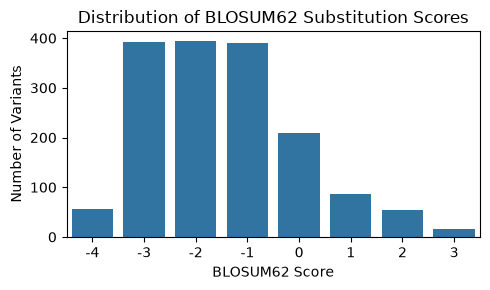

In [32]:
plt.figure(figsize=(5, 3))
sns.countplot(data=df,x="blosum62_score")
plt.xlabel("BLOSUM62 Score")
plt.ylabel("Number of Variants")
plt.title("Distribution of BLOSUM62 Substitution Scores")
plt.tight_layout()
plt.show()

In [33]:
subs_features = ["hydro_delta","charge_delta","volume_delta","blosum62_score"]
df[subs_features].corr().round(2)

,hydro_delta,charge_delta,volume_delta,blosum62_score
hydro_delta,1.00,0.10,-0.17,-0.56
charge_delta,0.10,1.00,-0.10,-0.08
volume_delta,-0.17,-0.10,1.00,-0.37
blosum62_score,-0.56,-0.08,-0.37,1.00


In [34]:
df[["blosum62_score", "label"]].corr().round(3)

,blosum62_score,label
blosum62_score,1.000,-0.112
label,-0.112,1.000
